In [5]:
import numpy as np
import matplotlib.pyplot as plt

#Defining a leapfrog function which intakes three parameters x, v and h, which are position, half time velocity and step-size respectively
def leapfrog(x, v, h):
    wp=1                #initializing the value of plasma frequency to 1 as stated in the assignemnt
    accln= -(wp**2)*x
    v= v + (accln*h)
    x= x + (v*h)
    return x,v


In [7]:
#Now for the task 2, we'll define the initial values for our problem which are already listed in assignment
x=0.5
v=0.0
h=0.1

#now initialize the half-step velocity
v= v - (h/2)* (-x)

#Now, we'll call the funtion
x_new, v_new= leapfrog(x,v,h)
print(x_new, v_new)

0.4975 -0.025


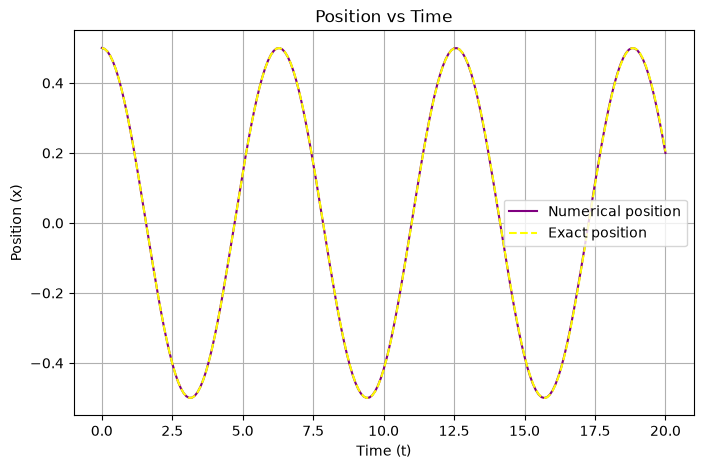

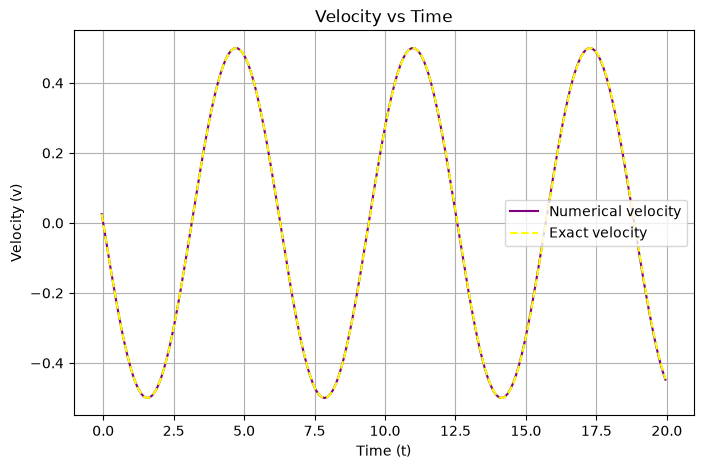

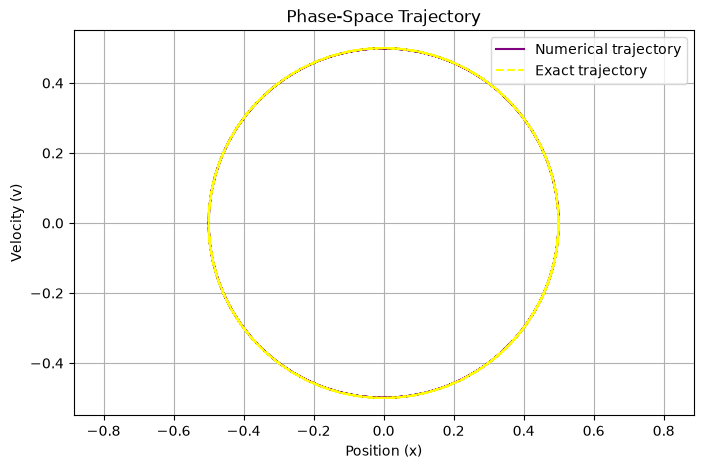

In [13]:
t_final = 20.0

# Now, we'll define the number of time steps using the variable N
N = int(t_final / h)

# Now, we'll create the time arrays for position and velocity
t_values = np.arange(N + 1) * h
t_half = (np.arange(N + 1) - 0.5) * h

# Now, we'll need to store the values of position and velocity at t_values and t_half respectively, hence we'll create the array using np.zeros
x_values = np.zeros(N + 1)
v_values = np.zeros(N + 1)

# Now, we'll store the initial values as we had stated earlier in the code after we defined the function
x_values[0] = x
v_values[0] = v

# Now we'll integrate all time steps usin the leapfrog function we created earlier
for n in range(N):
    x_values[n + 1], v_values[n + 1] = leapfrog(
        x_values[n], v_values[n], h
    )

# We'll also calculate the exact values of both x and v as the given function is a differential function
x_exact = 0.5 * np.cos(t_values)
v_exact = -0.5 * np.sin(t_half)

# Now plotting for position vs time
plt.figure(figsize=(8, 5))
plt.plot(t_values, x_values, label="Numerical position", color='purple')
plt.plot(t_values, x_exact, "--", label="Exact position", color= 'yellow')
plt.xlabel("Time (t)")
plt.ylabel("Position (x)")
plt.title("Position vs Time")
plt.legend()
plt.grid(True)
plt.show()

# Now plotting the velocity vs time graph
plt.figure(figsize=(8, 5))
plt.plot(t_half, v_values, label="Numerical velocity", color='purple')
plt.plot(t_half, v_exact, "--", label="Exact velocity", color='yellow')
plt.xlabel("Time (t)")
plt.ylabel("Velocity (v)")
plt.title("Velocity vs Time")
plt.legend()
plt.grid(True)
plt.show()

# Plot 3: Phase-space trajectory
v_centered = 0.5 * (v_values[:-1] + v_values[1:])

plt.figure(figsize=(8, 5))
plt.plot(x_values[:-1], v_centered, label="Numerical trajectory", color='purple')
plt.plot(
    x_exact[:-1],
    -0.5 * np.sin(t_values[:-1]),
    "--",
    label="Exact trajectory", color='yellow'
)
plt.xlabel("Position (x)")
plt.ylabel("Velocity (v)")
plt.title("Phase-Space Trajectory")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()
